# 03 - Datos geoespaciales de las calles de Algeciras
En este Notebook se añade la información geoespacial (geometría de cada calle) a los datos limpios de Algeciras obtenidos en el Notebook 01.

Los objetivos principales son:
* Cargar el archivo `251113 PAI Algeciras.kml` y comprobar cómo está estructurado.
* Encontrar el identificador que permita unir el KML con los datos limpios.
* Unir la geometría a los datos limpios, y comprobar qué calles quedan sin geometría.
* Visualizar el mapa de las calles sobre la ortofoto del PNOA.
* Guardar el conjunto de datos con geometría.

## Carga de datos

In [1]:
import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import numpy as np
import osmnx as ox
import re
import unicodedata
from rapidfuzz import fuzz, process
import pandas as pd

from urban_accessibility_ml.config import (
    EXTERNAL_DATA_DIR,
    RAW_DATA_DIR,
    INTERIM_DATA_DIR,
)

ALGECIRAS_DIR = RAW_DATA_DIR / "algeciras"
INTERIM_ALGECIRAS_DIR = INTERIM_DATA_DIR / "algeciras"

2026-10-24 08:59:05.273 | INFO     | urban_accessibility_ml.config:<module>:11 - PROJ_ROOT path is: /home/victor-pariente/dev/tfm/tfm-urban-accessibility-ml


El KML tiene varias capas. Listamos las capas disponibles y su tipo de geometría.

In [2]:
KML_FILE = ALGECIRAS_DIR / "251113 PAI Algeciras.kml"

import pyogrio
layers = pyogrio.list_layers(KML_FILE)
for name, _ in layers:
    gdf_layer = gpd.read_file(KML_FILE, layer=name)
    print(f"{name}: {gdf_layer.shape} {gdf_layer.geom_type.unique()}")

CALLES 1: (247, 34) ['LineString']
CALLES 2: (69, 15) ['LineString']
EDIFICIOS 1: (55, 43) ['Point']


Edificios con Incidencias: (11, 14) ['Point']
Edificios Finalizados: (37, 14) ['Point']
Edificios Visitados: (46, 14) ['Point']


Las capas `EDIFICIOS 1`, `Edificios con Incidencias`, `Edificios Finalizados` y `Edificios Visitados` son puntos de edificios, que no se utilizan en este análisis de calles. Las calles están en `CALLES 1` y `CALLES 2`, ambas de tipo `LineString`. Vemos qué contiene cada una.

In [3]:
gdf_calles1 = gpd.read_file(KML_FILE, layer="CALLES 1")
gdf_calles2 = gpd.read_file(KML_FILE, layer="CALLES 2")
print("CRS:", gdf_calles1.crs)

# Drop the empty / KML styling columns, and the photo links
cols_calles1 = ["Name", "REFERENCIA", "TIPOLOG__A", "ACC_TOTAL", "PROPUESTA", "PRESUPUESTO", "geometry"]
display(gdf_calles1[cols_calles1].head())
display(gdf_calles2[["Name", "Ancho", "description", "geometry"]].head())

CRS: EPSG:4326


,Name,REFERENCIA,TIPOLOG__A,ACC_TOTAL,PROPUESTA,PRESUPUESTO,geometry
0,Calle Juan Pérez Arriete,0001,Tráfico diferenciado 2 o más carriles,A,Mejora en Vía existente: Tráfico diferenciado ...,321.300 €,"LINESTRING Z (-5.44813 36.14284 0, -5.44801 36..."
1,Avenida Virgen del Carmen,0002,Tráfico diferenciado 2 o más carriles,A,Mejora en Vía existente: Tráfico diferenciado ...,967.900 €,"LINESTRING Z (-5.45592 36.14102 0, -5.45456 36..."
2,Paseo de la Conferencia (A),0003A,Tráfico diferenciado 2 o más carriles,A,Mejora en Vía existente: Tráfico diferenciado ...,141.300 €,"LINESTRING Z (-5.4442 36.12771 0, -5.44408 36...."
3,Paseo de la Conferencia (B),0003B,Tráfico diferenciado 2 o más carriles,C,Mejora en Vía existente: Tráfico diferenciado ...,277.100 €,"LINESTRING Z (-5.44295 36.12383 0, -5.4431 36...."
4,Calle Carteya,0004,Tráfico diferenciado 2 o más carriles,B,Mejora en Vía existente: Tráfico diferenciado ...,77.200 €,"LINESTRING Z (-5.44774 36.12298 0, -5.44803 36..."


,Name,Ancho,description,geometry
0,0176,15,Ancho: 15<br>descripción:,"LINESTRING Z (-5.44767 36.12286 0, -5.44763 36..."
1,0177,14,Ancho: 14<br>descripción:,"LINESTRING Z (-5.44721 36.1191 0, -5.44703 36...."
2,0178,11,Ancho: 11<br>descripción:,"LINESTRING Z (-5.44807 36.12232 0, -5.44801 36..."
3,0179,7,Ancho: 7<br>descripción:,"LINESTRING Z (-5.44807 36.12232 0, -5.44808 36..."
4,0180,10,Ancho: 10<br>descripción:,"LINESTRING Z (-5.44843 36.12266 0, -5.44819 36..."


* `CALLES 1` (247 calles) contiene el nombre, la `REFERENCIA`, y atributos de accesibilidad (letras A/B/C) además de la geometría.
* `CALLES 2` (69 calles) solo tiene la geometría y el ancho, y su `Name` es directamente la referencia de la calle (por ejemplo `0176`).

Por tanto, la clave de unión será la `REFERENCIA`. Algunas referencias están en ambas capas, comprobamos si coinciden sus geometrías.

In [4]:
# Same reference in both layers: compare geometries (in meters, EPSG:25830)
both = gdf_calles1.to_crs(25830).merge(gdf_calles2.to_crs(25830), left_on="REFERENCIA", right_on="Name", suffixes=("", "_2"))
dist = [a.hausdorff_distance(b) for a, b in zip(both.geometry, both.geometry_2)]
print("Referencias en ambas capas:", len(both))
print("Con geometría idéntica:", sum(d == 0 for d in dist), "| distancia máxima (m):", round(max(dist), 1))

Referencias en ambas capas: 24
Con geometría idéntica: 22 | distancia máxima (m): 23.9


Casi todas coinciden exactamente, y las que no difieren pocos metros. Se usará la geometría de `CALLES 1` y, si una calle solo aparece en `CALLES 2`, la de `CALLES 2`.

## Datos limpios
Cargamos los datos limpios (Notebook 01), que incluyen la columna `REFERENCIA`.

In [5]:
df_alg_streets = pd.read_csv(INTERIM_ALGECIRAS_DIR / "algeciras_streets_cleaned.csv", dtype={"REFERENCIA": str})
assert df_alg_streets["REFERENCIA"].is_unique
df_alg_streets.shape

(506, 73)

## Unión de los datos

In [6]:
# One geometry per reference, in EPSG:25830 (ETRS89 / UTM 30N) and without altitude.
# CALLES 1 has priority; CALLES 2 only fills the references missing in CALLES 1.
geom1 = gdf_calles1.set_index("REFERENCIA").geometry
geom2 = gdf_calles2.set_index("Name").geometry
geom = gpd.GeoSeries(geom1.combine_first(geom2), crs=gdf_calles1.crs).force_2d().to_crs(25830)
geom.name = "geometry"

gdf_alg_streets = gpd.GeoDataFrame(
    df_alg_streets.merge(geom, left_on="REFERENCIA", right_index=True, how="left"),
    geometry="geometry",
    crs=25830,
)

n_sin_geom = gdf_alg_streets.geometry.isna().sum()
print(f"Calles con geometría: {len(gdf_alg_streets) - n_sin_geom} de {len(gdf_alg_streets)}")
print("Referencias del KML sin calle en los datos limpios:", sorted(set(geom.index) - set(df_alg_streets["REFERENCIA"])))
assert len(gdf_alg_streets) == len(df_alg_streets)

Calles con geometría: 285 de 506
Referencias del KML sin calle en los datos limpios: ['0196', '0226', '0227', '0235', '0240', '0257', '0269']


Solo una parte de las calles tiene geometría en el KML. Comprobamos qué calles son las que faltan.

In [7]:
no_geom = gdf_alg_streets[gdf_alg_streets.geometry.isna()]
print(no_geom["REFERENCIA"].str[:4].astype(int).describe()[["min", "max"]])
display(no_geom[["REFERENCIA", "NOMBRE", "Barriada"]].head(10))
display(no_geom[["REFERENCIA", "NOMBRE", "Barriada"]].tail(10))

min       4.0
max    1000.0
Name: REFERENCIA, dtype: float64


,REFERENCIA,NOMBRE,Barriada
5,0004B,Calle Carteya B,La Banda del Río
17,0014B,Avenida Capitán Ontañón B,Centro
18,0014C,Avenida Capitán Ontañón C,Centro
43,0038B,Calle Doctor Power B,Adalides
51,0045B,Avenida América B,San Bernabé
60,0053B,Calle Benito Daza B,Adalides
74,0066B,Avenida Virgen de Europa B,Centro
127,0118B,Otro El Pajarete B,Pajarete
136,0126B,Avenida Blas Infante B,Centro
138,0127B,Calle José Román B,San Isidro


,REFERENCIA,NOMBRE,Barriada
496,0582,Avenida Campo de Gibraltar,La Menacha
497,0583,Avenida Caetania,La Menacha
498,0584,Calle Oporto,El Rosario
499,0585,Pasaje El Alcatraz,El Rinconcillo
500,0586,Calle Tórtola,El Rinconcillo
501,0587,Calle Bilbao,Centro
502,0588,Calle Anchera,Centro
503,0589,Calle Velarde,Centro
504,0590,Calle Huerta Ángel,Centro
505,1000,Sendero Playa de Getares,Getares


Se observa que:
* El KML solo incluye las calles de las primeras referencias (las calles con número de referencia más alto no tienen geometría), por lo que el KML parece incompleto respecto al xlsx.
* Las calles que están en dos barriadas (referencias terminadas en B o C, por ejemplo `0004B`) no tienen geometría propia: el KML dibuja la calle una sola vez, con la referencia sin letra. No se asigna esa geometría a los otros tramos para no inventar el trazado.

Queda pendiente investigar si existe una versión del KML con todas las calles.

## Completar la geometría con OpenStreetMap
Para las calles sin geometría en el KML se prueba a buscar su trazado en OpenStreetMap (OSM), emparejando los nombres de las calles de forma aproximada (fuzzy matching, con `rapidfuzz`). Como OSM parte las calles en muchos trozos, se une la geometría de todos los trozos con el mismo nombre.

In [8]:
# Streets of Algeciras from OpenStreetMap, one geometry per name (OSM splits the streets in pieces).
# The result is saved in data/external, because the Overpass server sometimes refuses the connection
OSM_STREETS_FILE = EXTERNAL_DATA_DIR / "algeciras" / "osm_streets_by_name.gpkg"
if not OSM_STREETS_FILE.exists():
    osm_streets = ox.features_from_place("Algeciras, Cádiz, España", tags={"highway": True})
    osm_streets = osm_streets[osm_streets.geom_type.isin(["LineString", "MultiLineString"])]
    osm_streets = osm_streets[osm_streets["name"].notna()].to_crs(25830)
    OSM_STREETS_FILE.parent.mkdir(parents=True, exist_ok=True)
    osm_streets.dissolve(by="name").reset_index()[["name", "geometry"]].to_file(OSM_STREETS_FILE)

osm_by_name = gpd.read_file(OSM_STREETS_FILE)
print(f"Calles de OSM con nombre distinto: {len(osm_by_name)}")

Calles de OSM con nombre distinto: 937


Unir por nombre tiene un riesgo: calles con el mismo nombre o con nombres parecidos en sitios distintos. Para reducirlo se usa la barriada: con las calles que ya tienen geometría en el KML se crea una zona aproximada de cada barriada (envolvente convexa con un margen de 150 m), y al buscar una calle solo compiten las calles de OSM que tocan la zona de su barriada. Las calles de barriadas sin ninguna calle en el KML se buscan en toda la ciudad.

In [9]:
# Approximate zone of each neighbourhood from its streets already drawn in the KML (before using OSM)
zones = (gdf_alg_streets[gdf_alg_streets.geometry.notna()]
         .dissolve(by="Barriada").buffer(150).convex_hull
         .rename("zone").reset_index())
print(f"Barriadas: {gdf_alg_streets['Barriada'].nunique()} | con zona (alguna calle en el KML): {len(zones)}")

Barriadas: 44 | con zona (alguna calle en el KML): 42


In [10]:
def normalize_street(name: str) -> str:
    """Lowercase, no accents, no section mark (A/B/C at the end) and no street type, to compare names."""
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode().lower()
    name = re.sub(r"\b([abc])$", "", name.strip())
    name = re.sub(r"\b(calle|avenida|avda|plaza|paseo|barriada|urbanizacion)\b", "", name)
    return re.sub(r"\s+", " ", name).strip()


osm_by_name["key"] = osm_by_name["name"].map(normalize_street)


def find_osm_street(row: pd.Series) -> pd.Series:
    """Closest OSM street name (token sort ratio, 0-100) among the OSM streets that touch the zone of the neighbourhood."""
    zone = zones.loc[zones["Barriada"] == row["Barriada"], "zone"]
    candidates = osm_by_name if zone.empty else osm_by_name[osm_by_name.intersects(zone.iloc[0])]
    match = process.extractOne(normalize_street(row["NOMBRE"]), candidates["key"], scorer=fuzz.token_sort_ratio)
    return pd.Series({"OSM_NOMBRE": osm_by_name.loc[match[2], "name"], "OSM_SCORE": match[1], "OSM_EN_ZONA": not zone.empty})


missing = gdf_alg_streets[gdf_alg_streets.geometry.isna()].copy()
missing[["OSM_NOMBRE", "OSM_SCORE", "OSM_EN_ZONA"]] = missing.apply(find_osm_street, axis=1)
print(f"Calles sin geometría: {len(missing)} | de barriadas sin zona: {(~missing['OSM_EN_ZONA']).sum()}")
display(missing["OSM_SCORE"].describe().round(1).to_frame().T)

# Matches below 90, sorted by score, to see where the quality drops
pd.set_option("display.max_rows", 100)
display(missing[missing["OSM_SCORE"] < 90].sort_values("OSM_SCORE")[["REFERENCIA", "NOMBRE", "Barriada", "OSM_NOMBRE", "OSM_SCORE", "OSM_EN_ZONA"]])

Calles sin geometría: 221 | de barriadas sin zona: 4


,count,mean,std,min,25%,50%,75%,max
OSM_SCORE,221.0,84.2,20.0,31.6,68.3,95.7,100.0,100.0


,REFERENCIA,NOMBRE,Barriada,OSM_NOMBRE,OSM_SCORE,OSM_EN_ZONA
316,0290,Calle Teide,Pelayo,Calle Sierra Aracena,31.578947,True
243,0226B,Calle Costa Rinconcillo Playa B,El Acebuchal,Calle del Chaparro,40.000000,True
242,0226A,Calle Costa Rinconcillo Playa,El Acebuchal,Calle del Chaparro,40.000000,True
364,0336,Avenida Hispanidad,Puerto,Avenida Villanueva,40.000000,True
465,0553,Calle Lugo,La Bajadilla,Calle Salmón,40.000000,True
470,0557,Calle Cabo Cope 2,San Bernabé,Calle de la Pulsera,41.666667,True
362,0334,Otro Polígono las Pilas,Los Pinos,Autovía del Mediterráneo,42.553191,True
326,0299,Calle Abogados de Oficio,El Acebuchal,Calle del Olivo,44.444444,True
393,0363,Plaza Neda,San Isidro,Calle Ancha,44.444444,True
382,0353,Calle Isaac Peral,La Caridad,Avenida Gesto por la Paz,44.444444,True


Se observa que:
* Dentro de la zona de la barriada, los emparejamientos con puntuación mayor o igual a 80 son en general correctos (diferencias de artículos, tildes o erratas, como `Calle Tulipán` con `Calle del Tulipan`). Quedan algunos dudosos, como `Calle Huerta Ángel` con `Calle Huerta Grande` o `Calle Anchera` con `Calle Ancha`, que habría que revisar a mano.
* Por debajo de 80 ya hay emparejamientos incorrectos (`Calle Jaén` con `Calle Bailén`, `Calle Muro` con `Calle Murillo`...).
* Las 4 calles de barriadas sin zona (`15 de Junio` y `Alamillos`) se buscan en toda la ciudad, donde hay más riesgo de falsos positivos; por eso exigen una puntuación mayor o igual a 90.

Las calles de OSM con marca de tramo (por ejemplo `Calle Albacete A` y `B`) reciben la geometría de toda la calle, por lo que es una aproximación: dos tramos de una misma calle tendrán la misma geometría.

In [11]:
# Threshold depends on the search area: lower inside the zone of the neighbourhood, higher in the whole city
OSM_THRESHOLD_ZONE = 80
OSM_THRESHOLD_CITY = 90

gdf_alg_streets["GEOM_FUENTE"] = np.where(gdf_alg_streets.geometry.notna(), "KML", None)
gdf_alg_streets[["OSM_NOMBRE", "OSM_SCORE", "OSM_EN_ZONA"]] = missing[["OSM_NOMBRE", "OSM_SCORE", "OSM_EN_ZONA"]]

accepted = missing[missing["OSM_SCORE"] >= np.where(missing["OSM_EN_ZONA"], OSM_THRESHOLD_ZONE, OSM_THRESHOLD_CITY)]
osm_geometry = osm_by_name.set_index("name").geometry
gdf_alg_streets.loc[accepted.index, "geometry"] = gpd.GeoSeries(
    osm_geometry.loc[accepted["OSM_NOMBRE"]].values, index=accepted.index, crs=25830
)
gdf_alg_streets.loc[accepted.index, "GEOM_FUENTE"] = "OSM"

print(gdf_alg_streets["GEOM_FUENTE"].value_counts(dropna=False))
print(f"Calles con geometría: {gdf_alg_streets.geometry.notna().sum()} de {len(gdf_alg_streets)}")

GEOM_FUENTE
KML     285
OSM     150
None     71
Name: count, dtype: int64
Calles con geometría: 435 de 506


## Clases de accesibilidad (semáforo)
Se divide la escala de la puntuación global (`PUNT_TOTAL`, de 0 a 5) en tres tercios iguales y se asigna una clase a cada calle: **A** (verde, tercio superior), **B** (amarillo, tercio central) y **C** (rojo, tercio inferior).

Se comprueba que esta regla reproduce la clase `PIC_TOTAL` que ya venía en los datos.

In [12]:
# Traffic light classes: thirds of the score scale (0-5); C < 1/3 <= B < 2/3 <= A
SCALE = 5
CLASS_COLORS = {"A": "#43a047", "B": "#fdd835", "C": "#e53935"}
gdf_alg_streets["CLASE"] = pd.Series(
    np.select([gdf_alg_streets["PUNT_TOTAL"] >= SCALE * 2 / 3, gdf_alg_streets["PUNT_TOTAL"] >= SCALE / 3], ["A", "B"], default="C"),
    index=gdf_alg_streets.index,
).astype(pd.CategoricalDtype(["A", "B", "C"], ordered=True))
display(gdf_alg_streets["CLASE"].value_counts().sort_index().to_frame("calles").assign(porcentaje=lambda d: (d["calles"] / d["calles"].sum() * 100).round(1)))

# Same rule as the original class of the dataset
assert (gdf_alg_streets["CLASE"] == gdf_alg_streets["PIC_TOTAL"]).all()

,calles,porcentaje
CLASE,,
A,28,5.5
B,284,56.1
C,194,38.3


## Visualización
Mapa de las calles con geometría (del KML y de OSM) sobre la ortofoto del PNOA (servicio WMTS del IGN), coloreadas por la puntuación global de accesibilidad (`PUNT_TOTAL`).

In [13]:
# PNOA orthophoto tiles (IGN WMTS); contextily fills {z}, {x} and {y}
PNOA_URL = (
    "https://www.ign.es/wmts/pnoa-ma?request=GetTile&service=WMTS&VERSION=1.0.0"
    "&Layer=OI.OrthoimageCoverage&Style=default&Format=image/jpeg"
    "&TileMatrixSet=GoogleMapsCompatible&TileMatrix={z}&TileRow={y}&TileCol={x}"
)

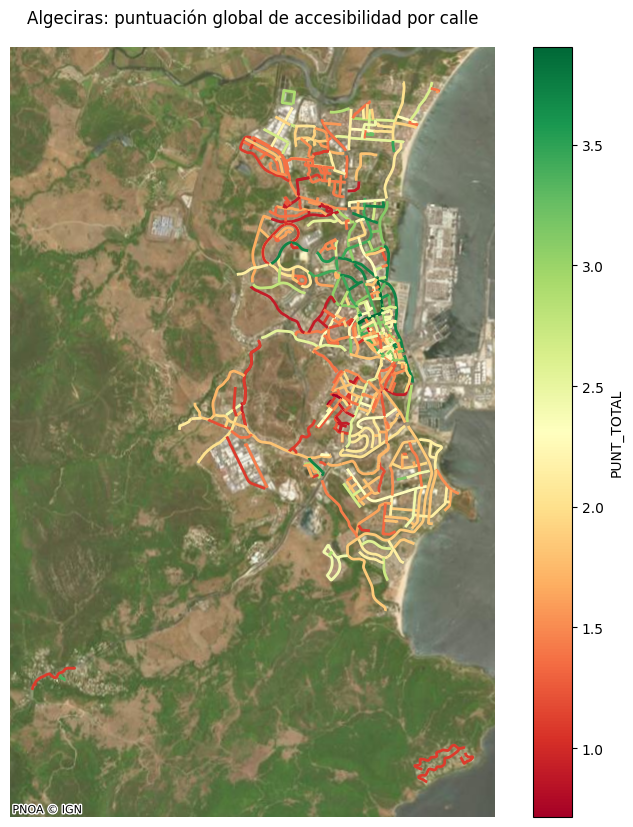

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))
gdf_alg_streets.dropna(subset=["geometry"]).plot(column="PUNT_TOTAL", cmap="RdYlGn", linewidth=2, legend=True, ax=ax,
                                                   legend_kwds={"label": "PUNT_TOTAL"})
ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
ax.set_title("Algeciras: puntuación global de accesibilidad por calle")
ax.set_axis_off()
plt.show()

Mapa con el semáforo (clases A, B y C).

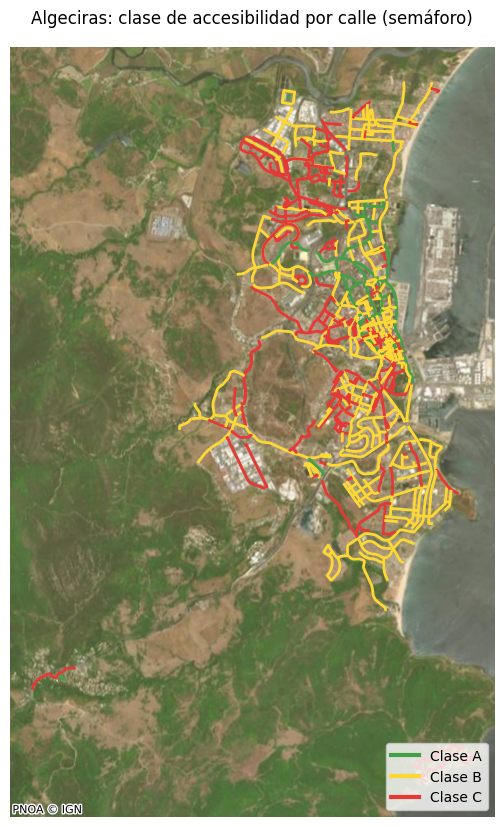

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))
streets_geo = gdf_alg_streets.dropna(subset=["geometry"])
streets_geo.plot(color=streets_geo["CLASE"].map(CLASS_COLORS), linewidth=2, ax=ax)
ax.legend(handles=[Line2D([0], [0], color=c, lw=3, label=f"Clase {k}") for k, c in CLASS_COLORS.items()], loc="lower right")
ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
ax.set_title("Algeciras: clase de accesibilidad por calle (semáforo)")
ax.set_axis_off()
plt.show()

Mapa por tipología de la calle (`TIPOLOGÍA`).

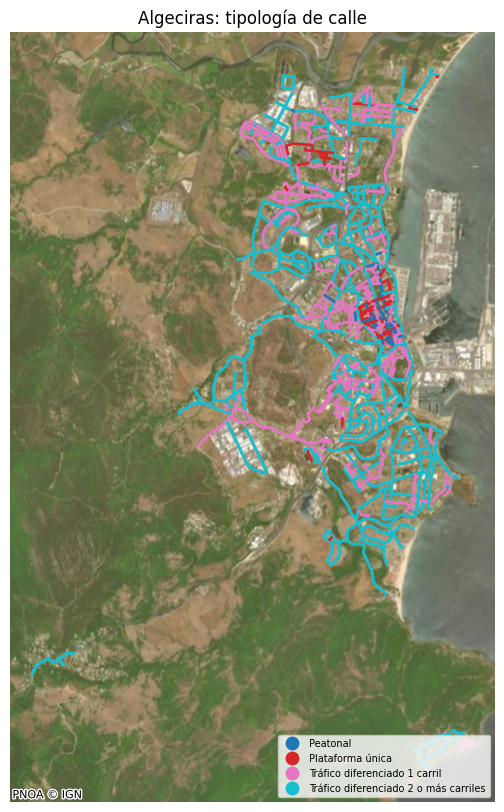

In [16]:
fig, ax = plt.subplots(figsize=(10, 10))
gdf_alg_streets.dropna(subset=["geometry"]).assign(TIPOLOGÍA=lambda d: d["TIPOLOGÍA"].astype(str)).plot(
    column="TIPOLOGÍA", categorical=True, linewidth=2, legend=True, ax=ax,
    legend_kwds={"loc": "lower right", "fontsize": 7},
)
ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
ax.set_title("Algeciras: tipología de calle")
ax.set_axis_off()
plt.show()

## Ejemplos de calles por clase
Para ver mejor la clasificación sobre la ortofoto, se elige una calle de cada clase (A, B y C): la de longitud más cercana a la mediana de su clase, entre las que tienen geometría del KML. La calle elegida se dibuja más gruesa, y alrededor se muestran las calles vecinas con su clase.

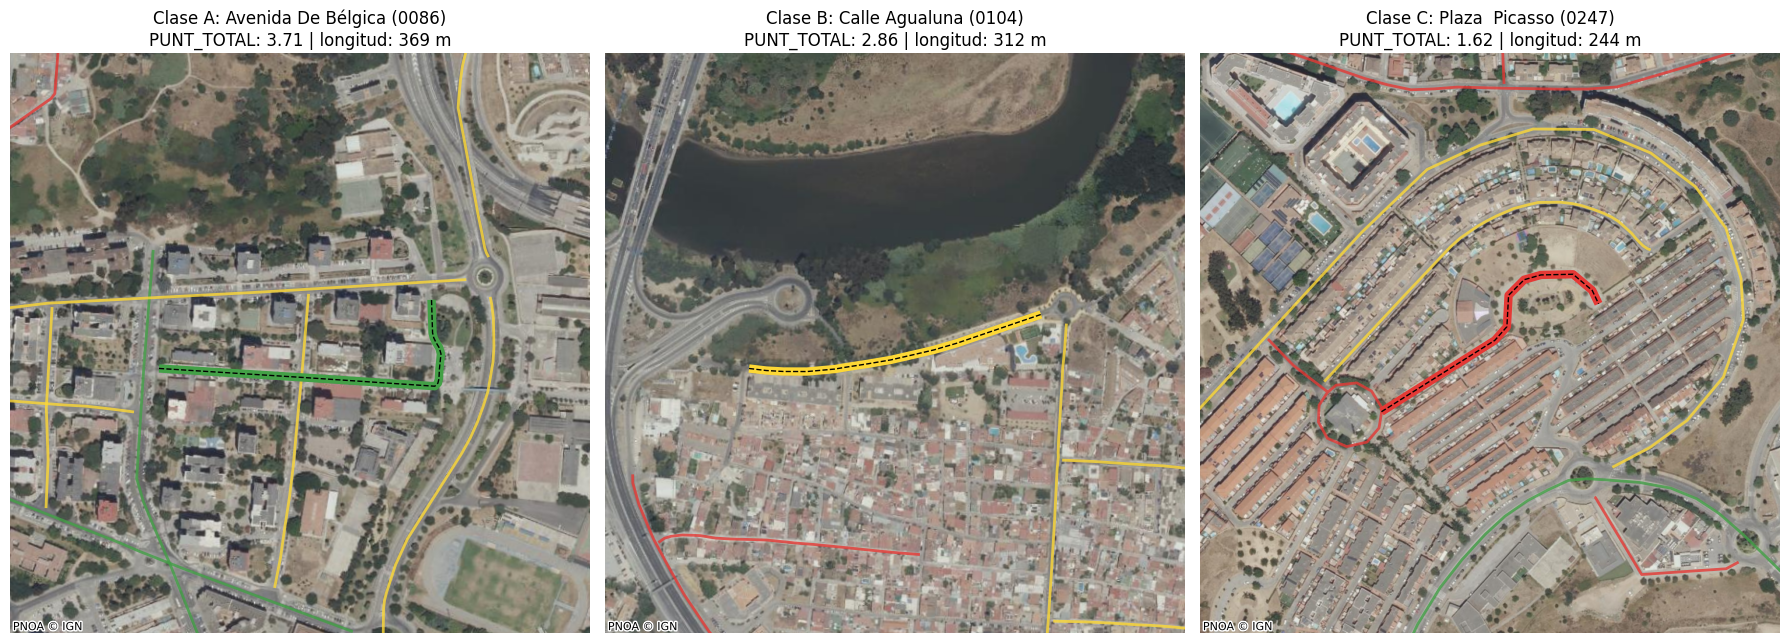

In [17]:
# One example street per class: the one whose length is closest to the median length of its class - AI generated
streets_geo = gdf_alg_streets.dropna(subset=["geometry"]).loc[lambda d: d["GEOM_FUENTE"] == "KML"]
streets_geo = streets_geo.assign(length_m=streets_geo.length)
examples = {}
for cls in ["A", "B", "C"]:
    group = streets_geo[streets_geo["CLASE"] == cls]
    examples[cls] = (group["length_m"] - group["length_m"].median()).abs().idxmin()

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (cls, idx) in zip(axes, examples.items()):
    street = streets_geo.loc[idx]
    minx, miny, maxx, maxy = street.geometry.bounds
    half = max(maxx - minx, maxy - miny) / 2 + 150  # square view around the street, with a margin of 150 m
    cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    streets_geo.plot(color=streets_geo["CLASE"].map(CLASS_COLORS), linewidth=2, alpha=0.8, ax=ax)
    streets_geo.loc[[idx]].plot(color=CLASS_COLORS[cls], linewidth=6, ax=ax)
    streets_geo.loc[[idx]].plot(color="black", linewidth=1, linestyle="--", ax=ax)
    ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
    ax.set_title(f"Clase {cls}: {street['NOMBRE']} ({street['REFERENCIA']})\nPUNT_TOTAL: {street['PUNT_TOTAL']:.2f} | longitud: {street['length_m']:.0f} m")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

Mismas calles de ejemplo, con más zoom: se muestra un tramo de unos 80 m centrado en el punto medio de la calle, para ver cómo es el entorno de la calle sobre la ortofoto.

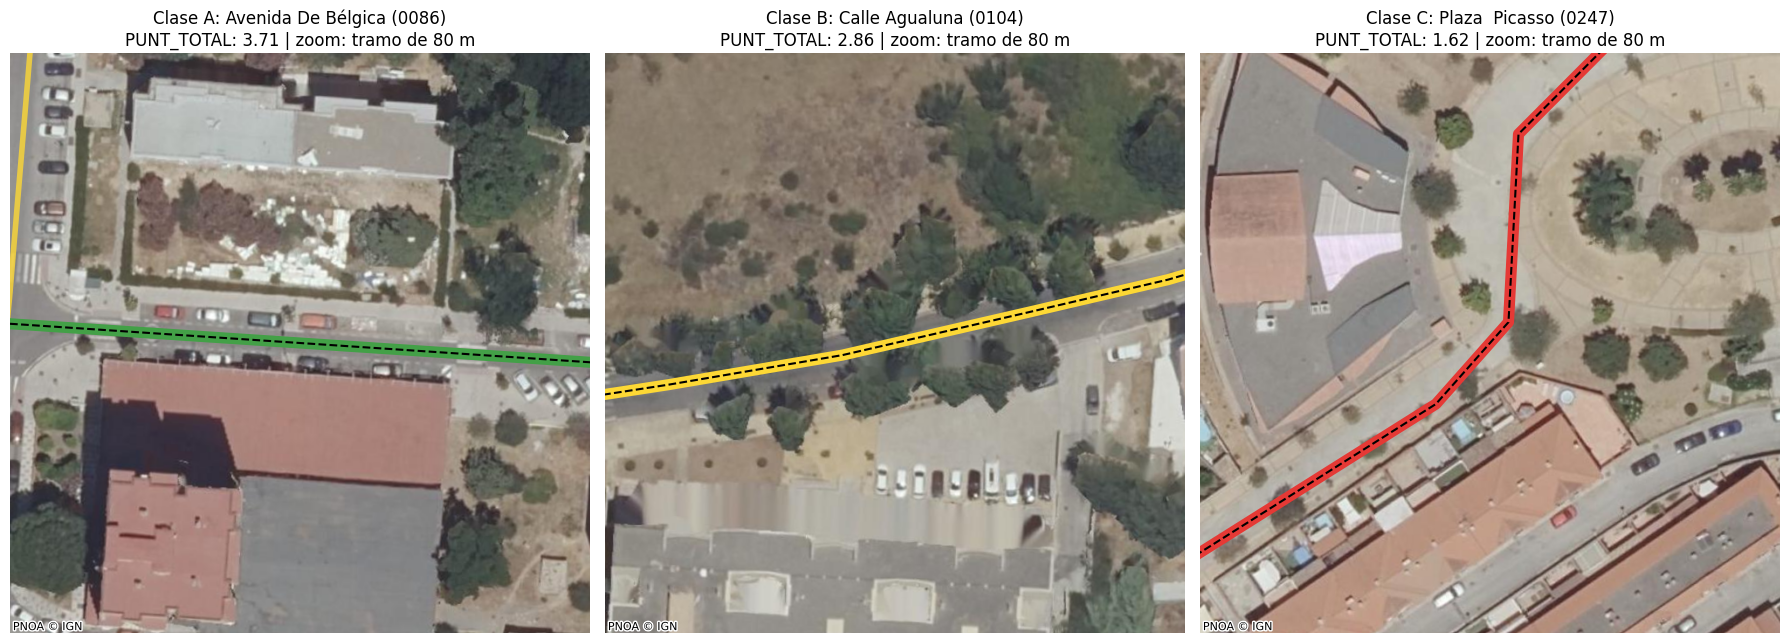

In [18]:
# Close-up of a short section of each example street (80 m x 80 m around the midpoint of the street) - AI generated
HALF_VIEW = 40  # meters

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, (cls, idx) in zip(axes, examples.items()):
    street = streets_geo.loc[idx]
    mid = street.geometry.interpolate(0.5, normalized=True)
    ax.set_xlim(mid.x - HALF_VIEW, mid.x + HALF_VIEW)
    ax.set_ylim(mid.y - HALF_VIEW, mid.y + HALF_VIEW)
    streets_geo.plot(color=streets_geo["CLASE"].map(CLASS_COLORS), linewidth=4, alpha=0.8, ax=ax)
    streets_geo.loc[[idx]].plot(color=CLASS_COLORS[cls], linewidth=8, ax=ax)
    streets_geo.loc[[idx]].plot(color="black", linewidth=1.5, linestyle="--", ax=ax)
    ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
    ax.set_title(f"Clase {cls}: {street['NOMBRE']} ({street['REFERENCIA']})\nPUNT_TOTAL: {street['PUNT_TOTAL']:.2f} | zoom: tramo de {2 * HALF_VIEW} m")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Mapa de calor por barrio
Para cada barriada se calcula la media (y la mediana) de la puntuación global (`PUNT_TOTAL`) de sus calles. El mapa pinta cada zona con una escala de colores continua, del rojo fuerte (valor más bajo) al verde fuerte (valor más alto), ajustada al rango de las barriadas para destacar sus diferencias. Se usa la mediana (`STAT = "median"`), pero se puede cambiar a la media. La mediana se calcula con todas las calles de la barriada (también las que no tienen geometría), pero solo se dibujan las barriadas con zona (42 de 44). El mapa se ajusta al casco urbano, dejando fuera `Pelayo` y `El Faro`.

,mean,median,count,CLASE
Barriada,,,,
La Reconquista,3.54,3.71,7,A
Puerto,3.22,3.10,3,B
El Rosario,2.52,2.67,17,B
San José Artesano,2.55,2.48,6,B
La Menacha,2.44,2.48,6,B
Centro,2.53,2.43,79,B
La Aldea,2.25,2.43,3,B
San Isidro,2.39,2.36,18,B
Getares,2.26,2.14,9,B


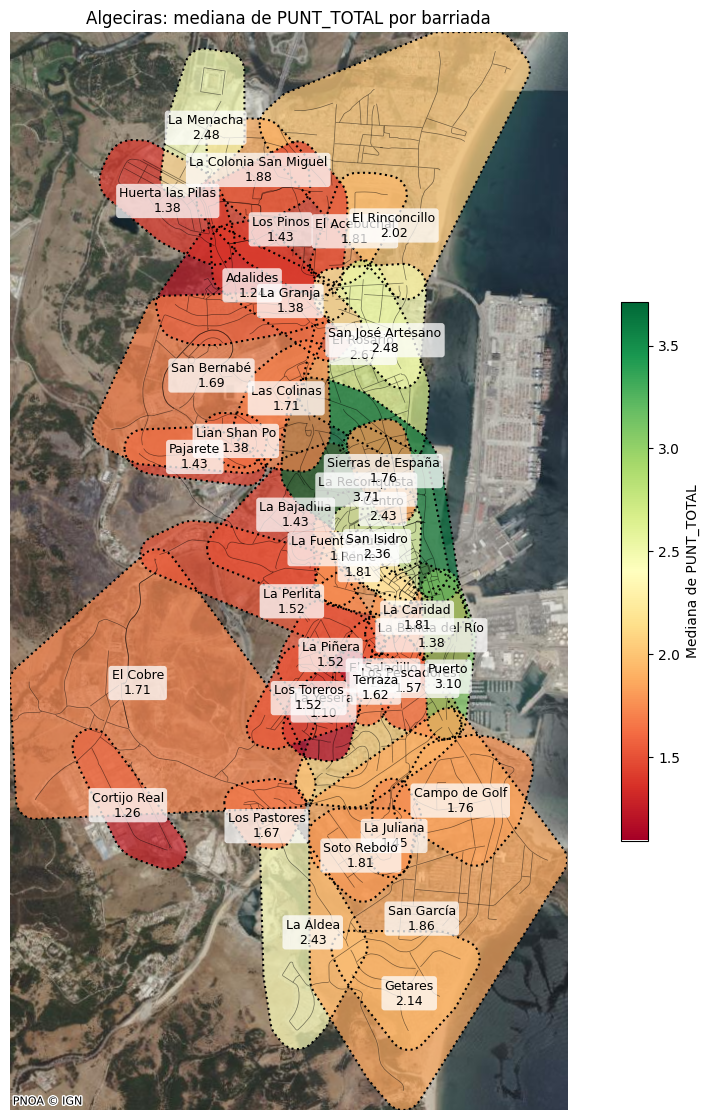

In [19]:
# Zones of the neighbourhoods computed before (hull of the KML streets), with a standard geometry column - AI generated
zones = gpd.GeoDataFrame(zones.rename(columns={"zone": "geometry"}), geometry="geometry", crs=gdf_alg_streets.crs)

STAT = "median"  # "mean" or "median"
scores = gdf_alg_streets.groupby("Barriada")["PUNT_TOTAL"].agg(["mean", "median", "count"])
scores["CLASE"] = np.select([scores[STAT] >= SCALE * 2 / 3, scores[STAT] >= SCALE / 3], ["A", "B"], default="C")
display(scores.sort_values(STAT, ascending=False).round(2))

areas = zones.merge(scores, left_on="Barriada", right_index=True)
streets_geo = gdf_alg_streets.dropna(subset=["geometry"])

fig, ax = plt.subplots(figsize=(14, 14))
# Continuous scale from strong red (lowest value) to strong green (highest), adjusted to the range of the neighbourhoods
norm = Normalize(vmin=scores[STAT].min(), vmax=scores[STAT].max())
cmap = plt.get_cmap("RdYlGn")
areas.plot(ax=ax, color=[cmap(norm(value)) for value in areas[STAT]], alpha=0.7)
areas.boundary.plot(ax=ax, color="black", linestyle=":", linewidth=1.5)
streets_geo.plot(color="black", linewidth=0.5, alpha=0.5, ax=ax)
for _, area in areas.iterrows():
    point = area.geometry.representative_point()
    ax.annotate(f"{area['Barriada']}\n{area[STAT]:.2f}", (point.x, point.y), ha="center", va="center", fontsize=9, color="black",
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.75))
minx, miny, maxx, maxy = areas[~areas["Barriada"].isin(["Pelayo", "El Faro"])].total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.5, label=f"{'Media' if STAT == 'mean' else 'Mediana'} de PUNT_TOTAL")
ctx.add_basemap(ax, source=PNOA_URL, crs=gdf_alg_streets.crs, attribution="PNOA © IGN")
ax.set_title(f"Algeciras: {'media' if STAT == 'mean' else 'mediana'} de PUNT_TOTAL por barriada")
ax.set_axis_off()
plt.show()

## Guardado del conjunto de datos con geometría
Se guarda en `data/interim/algeciras` en formato GeoJSON, con las calles sin geometría con geometría nula.

In [20]:
gdf_alg_streets.to_file(INTERIM_ALGECIRAS_DIR / "algeciras_streets_geo.geojson", driver="GeoJSON")